Suhas Gullapelli - NBA Player Stat Projections

Projects a player's **points, rebounds, and assists** for a game from:
- **Recent form**: averages over the last 5 and 10 games, a weighted longer-term average, and season-to-date averages (basic and advanced stats: usage, assist %, rebound %, true shooting, PIE, possessions)
- **Head-to-head**: the player's past games against this opponent, and how that compares to their usual level
- **Opponent**: the opponent's last 10 games: defensive rating, pace, and points/rebounds/assists allowed
- **Game context**: home or away, rest days, back-to-backs, playoffs, and the player's own team's form
- **Players out**: rotation players missing for either team (injuries, rest), and the minutes, points, assists and shots they take with them. The game logs only list players who played, so a player counts as out when he played in at least 2 of his team's previous 10 games and isn't in this one. For upcoming games `project.py` uses the current ESPN injury report.

Data comes from `collect_data.py` (NBA stats API, 2015-16 to now). Feature code is in `features.py`; every feature uses only games played before the one being predicted.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from features import load_data, build_features, upcoming_features, FEATURES, TARGETS

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
players, teams = load_data()
df = build_features(players, teams)
print(df.shape)
df[['PLAYER_NAME', 'GAME_DATE', 'MATCHUP', 'PTS', 'PTS_L5', 'PTS_L10', 'PTS_SEASON', 'PTS_H2H', 'H2H_GP',
    'OPP_DEF_RATING', 'TEAM_OUT_PTS', 'OPP_OUT_PTS', 'REST_DAYS']].tail()

(304029, 156)


,PLAYER_NAME,GAME_DATE,MATCHUP,PTS,PTS_L5,PTS_L10,PTS_SEASON,PTS_H2H,H2H_GP,OPP_DEF_RATING,TEAM_OUT_PTS,OPP_OUT_PTS,REST_DAYS
304024,Jordan Hawkins,2026-11-08,CHI vs. PHI,9,4.2,8.900000,2.000000,9.600,5,106.57,42.600000,5.861111,4.0
304025,Matas Buzelis,2026-11-08,CHI vs. PHI,19,11.6,12.800000,12.875000,9.625,8,106.57,42.600000,5.861111,4.0
304026,VJ Edgecombe,2026-11-08,PHI @ CHI,13,14.8,12.700000,13.222222,16.250,4,124.15,5.861111,42.600000,2.0
304027,Noa Essengue,2026-11-08,CHI vs. PHI,10,5.4,3.555556,4.571429,8.000,1,106.57,42.600000,5.861111,4.0
304028,Caleb Wilson,2026-11-08,CHI vs. PHI,18,17.8,19.500000,19.500000,24.000,1,106.57,42.600000,5.861111,4.0


## Do teammates being out matter?

Compare players' points, minutes and shots to their last-10 averages, grouped by how many more teammate points per game are missing than over their last 10 games.

In [3]:
played = df[(df['MIN'] > 0) & (df['CAREER_GP'] >= 10) & (df['MIN_L10'] >= 20)].copy()
played['Extra teammate PTS out'] = pd.cut(played['TEAM_OUT_PTS_DIFF'], bins=[-200, -10, -3, 3, 10, 20, 200],
                                          labels=['10+ fewer', '3-10 fewer', 'About the same', '3-10 more',
                                                  '10-20 more', '20+ more'])
for c in ['PTS', 'MIN', 'FGA']:
    played[f'{c} vs last 10'] = played[c] - played[f'{c}_L10']
summary = played.groupby('Extra teammate PTS out')[['PTS vs last 10', 'MIN vs last 10', 'FGA vs last 10']].mean()
summary['Games'] = played.groupby('Extra teammate PTS out').size()
summary.round(2)

,PTS vs last 10,MIN vs last 10,FGA vs last 10,Games
Extra teammate PTS out,,,,
10+ fewer,-1.50,-2.51,-1.20,41740
3-10 fewer,-0.73,-1.14,-0.58,38884
About the same,-0.23,-0.13,-0.16,34380
3-10 more,0.23,0.56,0.25,28706
10-20 more,0.88,1.15,0.74,22379
20+ more,2.05,1.91,1.75,15859


## Training and test sets

Only games where the player played and had at least 5 earlier games are used. The model trains on 2015-16 through 2024-25 and is tested on the full **2025-26** season, so it is judged on games from a season it never saw.

In [4]:
data = df[(df['MIN'] > 0) & (df['CAREER_GP'] >= 5)].copy()

TEST_SEASON = '2025-26'
train = data[data['SEASON_YEAR'] < TEST_SEASON]
test = data[data['SEASON_YEAR'] == TEST_SEASON]

X_train, X_test = train[FEATURES], test[FEATURES]
print(len(train), 'training games,', len(test), 'test games,', len(FEATURES), 'features')

265273 training games, 28062 test games, 84 features


## Baselines

A projection is only useful if it beats the simple averages people already use, so those are the baselines: the player's last-10-game average and season average.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def scores(y_true, y_pred):
    mask = ~np.isnan(y_pred)
    return {'MAE': mean_absolute_error(y_true[mask], y_pred[mask]),
            'RMSE': np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))}

results = []
for t in TARGETS:
    y = test[t].values
    # Early in a season there's no season average yet, so fall back to the last-10 average
    season_avg = test[f'{t}_SEASON'].fillna(test[f'{t}_L10']).values
    results.append({'Stat': t, 'Method': 'Last 10 games average', **scores(y, test[f'{t}_L10'].values)})
    results.append({'Stat': t, 'Method': 'Season average', **scores(y, season_avg)})
pd.DataFrame(results).round(3)

,Stat,Method,MAE,RMSE
0,PTS,Last 10 games average,4.678,6.142
1,PTS,Season average,4.708,6.196
2,REB,Last 10 games average,1.938,2.559
3,REB,Season average,1.928,2.554
4,AST,Last 10 games average,1.369,1.870
5,AST,Season average,1.366,1.870


## Training the models

One gradient boosting model per stat. Gradient boosting handles missing values on its own (e.g. no head-to-head history yet), so nothing needs to be filled in.

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor

models, predictions = {}, {}
for t in TARGETS:
    model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=100, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.1, random_state=42)
    model.fit(X_train, train[t])
    models[t] = model
    predictions[t] = model.predict(X_test)
    results.append({'Stat': t, 'Method': 'Gradient Boosting model', **scores(test[t].values, predictions[t])})
    print(t, 'trained with', model.n_iter_, 'trees')

PTS trained with 172 trees


REB trained with 171 trees


AST trained with 202 trees


For comparison, the same model without the players-out features:

In [7]:
no_out = [f for f in FEATURES if 'OUT_' not in f]
for t in TARGETS:
    m = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31,
                                      min_samples_leaf=100, l2_regularization=1.0,
                                      early_stopping=True, validation_fraction=0.1, random_state=42)
    m.fit(train[no_out], train[t])
    results.append({'Stat': t, 'Method': 'Model without players out', **scores(test[t].values, m.predict(test[no_out]))})

In [8]:
comparison = pd.DataFrame(results).pivot(index='Method', columns='Stat', values='MAE')[TARGETS]
comparison = comparison.loc[['Season average', 'Last 10 games average', 'Model without players out',
                             'Gradient Boosting model']]
print('Mean absolute error on the 2025-26 season (lower is better)')
comparison.round(3)

Mean absolute error on the 2025-26 season (lower is better)


Stat,PTS,REB,AST
Method,,,
Season average,4.708,1.928,1.366
Last 10 games average,4.678,1.938,1.369
Model without players out,4.539,1.877,1.329
Gradient Boosting model,4.453,1.850,1.316


In [9]:
improvement = (1 - comparison.loc['Gradient Boosting model'] / comparison.loc['Last 10 games average']) * 100
print('Model error vs. last-10 average:')
for t in TARGETS:
    print(f'  {t}: {improvement[t]:.1f}% lower')

Model error vs. last-10 average:
  PTS: 4.8% lower
  REB: 4.6% lower
  AST: 3.8% lower


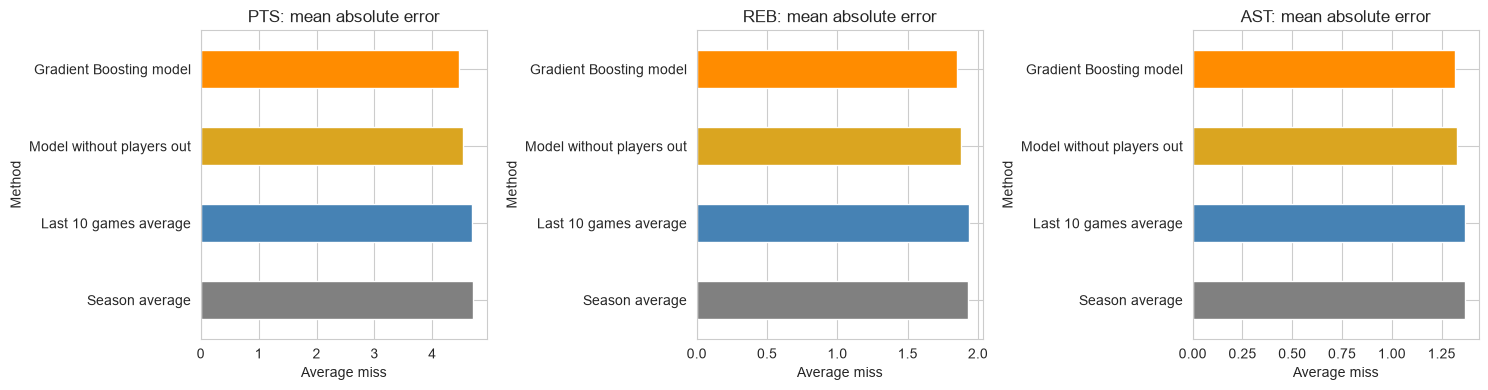

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, TARGETS):
    comparison[t].plot(kind='barh', ax=ax, color=['gray', 'steelblue', 'goldenrod', 'darkorange'])
    ax.set_title(f'{t}: mean absolute error')
    ax.set_xlabel('Average miss')
plt.tight_layout()
plt.show()

## How close are the projections?

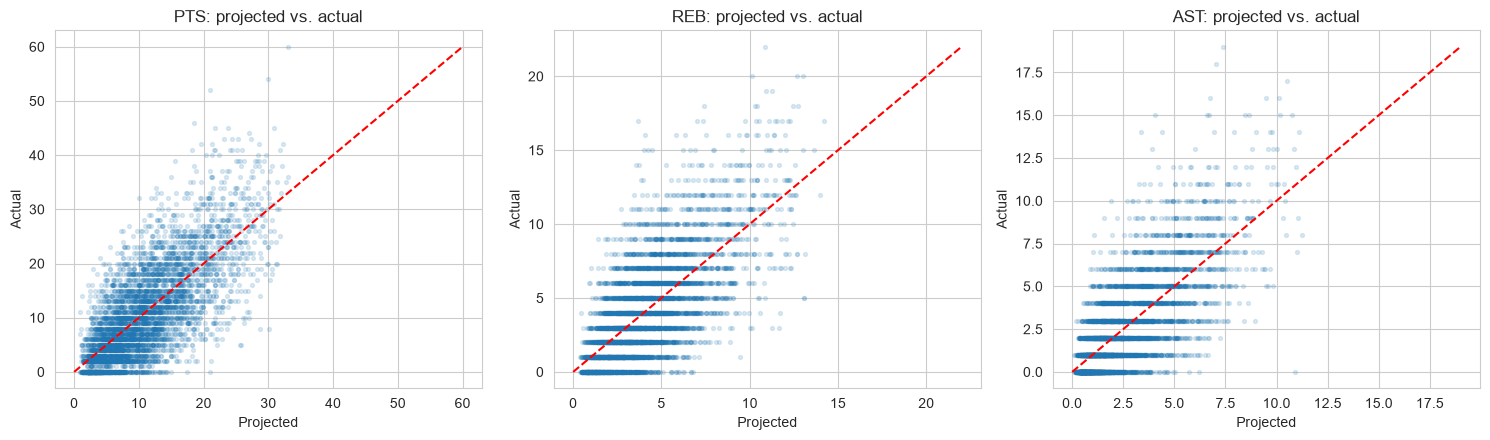

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, t in zip(axes, TARGETS):
    sample = test.assign(pred=predictions[t]).sample(5000, random_state=42)
    ax.scatter(sample['pred'], sample[t], alpha=0.15, s=8)
    top = sample[[t, 'pred']].max().max()
    ax.plot([0, top], [0, top], color='red', linestyle='--')
    ax.set_title(f'{t}: projected vs. actual')
    ax.set_xlabel('Projected')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [12]:
# Average miss for players by how many minutes they usually play
test_eval = test.assign(**{f'{t}_PRED': predictions[t] for t in TARGETS})
test_eval['Minutes'] = pd.cut(test_eval['MIN_L10'], bins=[0, 15, 25, 32, 48],
                              labels=['Under 15', '15-25', '25-32', '32+'])
test_eval.groupby('Minutes').apply(
    lambda g: pd.Series({t: mean_absolute_error(g[t], g[f'{t}_PRED']) for t in TARGETS} | {'Games': len(g)})
).round(2)

,PTS,REB,AST,Games
Minutes,,,,
Under 15,3.12,1.50,0.87,6366.0
15-25,4.23,1.84,1.22,9612.0
25-32,5.07,2.04,1.51,7839.0
32+,5.84,2.05,1.84,4245.0


## Which features matter?

Permutation importance shuffles one feature at a time and measures how much worse the points model gets. This shows whether head-to-head and opponent features add anything beyond recent form.

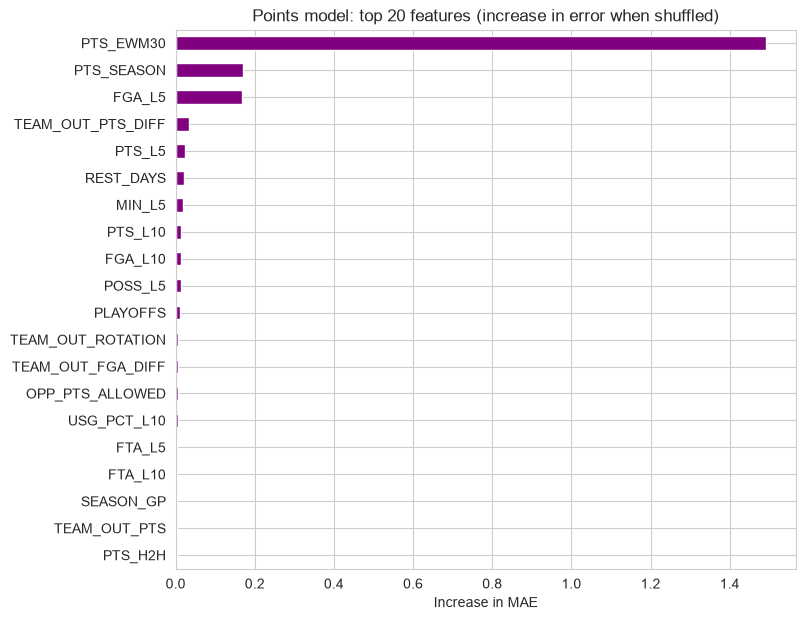

In [13]:
from sklearn.inspection import permutation_importance

sample = test.sample(20000, random_state=42)
result = permutation_importance(models['PTS'], sample[FEATURES], sample['PTS'],
                                scoring='neg_mean_absolute_error', n_repeats=3, random_state=42)
importance = pd.Series(result.importances_mean, index=FEATURES).sort_values()
importance.tail(20).plot(kind='barh', figsize=(8, 7), color='purple',
                         title='Points model: top 20 features (increase in error when shuffled)')
plt.xlabel('Increase in MAE')
plt.show()

In [14]:
def group_of(feature):
    if 'OUT_' in feature:
        return 'Players out'
    if 'H2H' in feature:
        return 'Head-to-head'
    if feature.startswith('OPP_'):
        return 'Opponent'
    if feature.startswith('TEAM_'):
        return 'Own team'
    if feature in ('REST_DAYS', 'BACK_TO_BACK', 'HOME', 'PLAYOFFS'):
        return 'Game context'
    return 'Player form'

importance.groupby(importance.index.map(group_of)).sum().sort_values(ascending=False).round(4)

Player form     1.9417
Players out     0.0577
Game context    0.0335
Opponent        0.0108
Head-to-head    0.0025
Own team       -0.0000
dtype: float64

## Final models

Refit on every season, including 2025-26 and the current season so far, and save them for `project.py`.

In [15]:
import joblib
import sklearn

final_models = {}
for t in TARGETS:
    model = HistGradientBoostingRegressor(max_iter=models[t].n_iter_, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=100, l2_regularization=1.0,
                                          early_stopping=False, random_state=42)
    final_models[t] = model.fit(data[FEATURES], data[t])

joblib.dump({'models': final_models, 'features': FEATURES, 'sklearn_version': sklearn.__version__,
             'test_mae': comparison.loc['Gradient Boosting model'].round(2).to_dict()},
            'projection_models.joblib')

['projection_models.joblib']

## Projecting upcoming games

`out` lists players who won't play (either team); `project.py` fills it in from the ESPN injury report. The last two rows are the same game with and without a teammate.

In [16]:
def project(player, opponent, home, game_date=None, out=()):
    row, rotations = upcoming_features(players, teams, player, opponent, home, game_date, out_names=out)
    team_out = rotations[rotations['OUT'] & (rotations['TEAM_ID'] == row['TEAM_ID'].iloc[0])]
    projection = {t: round(float(final_models[t].predict(row[FEATURES])[0]), 1) for t in TARGETS}
    return {'Player': row['PLAYER_NAME'].iloc[0], 'Matchup': row['MATCHUP'].iloc[0], **projection,
            'Last 10 PTS': round(row['PTS_L10'].iloc[0], 1), 'H2H games': int(row['H2H_GP'].iloc[0]),
            'H2H PTS': round(row['PTS_H2H'].iloc[0], 1), 'Teammates out': ', '.join(team_out['PLAYER_NAME'])}

pd.DataFrame([
    project('Luka Doncic', 'BOS', home=True),
    project('Nikola Jokic', 'MIN', home=False),
    project('Jayson Tatum', 'NYK', home=True),
    project('Victor Wembanyama', 'OKC', home=True),
    project('Nikola Jokic', 'MIN', home=False, out=['Jamal Murray']),
])

,Player,Matchup,PTS,REB,AST,Last 10 PTS,H2H games,H2H PTS,Teammates out
0,Luka Dončić,LAL vs. BOS,33.0,7.2,7.0,37.3,18,29.7,
1,Nikola Jokić,DEN @ MIN,21.2,10.7,7.6,23.8,60,25.3,
2,Jayson Tatum,BOS vs. NYK,24.0,7.3,6.7,26.4,35,24.8,
3,Victor Wembanyama,SAS vs. OKC,24.7,10.8,2.9,29.1,17,21.2,
4,Nikola Jokić,DEN @ MIN,22.7,10.7,8.3,23.8,60,25.3,Jamal Murray
